# **Installing all the relavant libraries**

In [1]:
pip install pandas numpy scikit-learn

Note: you may need to restart the kernel to use updated packages.


**Python script designed for handling missing data in automotive datasets—a common task when working with sensor logs (e.g., Engine RPM, Throttle Position, Coolant Temperature) that frequently suffer from dropouts or transmission errors.**

This script uses pandas and scikit-learn to demonstrate three fundamental data imputation techniques used in automotive testing analysis:
1. Forward Fill (ffill): Best for continuous time-series sensor streams where the next reading is likely similar to the last.
2. Mean/Median Imputation: Best for steady-state parameters.
3. K-Nearest Neighbors (KNN) Imputation: Best for capturing complex, multi-variable engine relationships.


In [2]:
import numpy as np
import pandas as pd
from sklearn.impute import KNNImputer

# 1. GENERATE SIMULATED AUTOMOTIVE SENSOR DATA
# Simulating an engine dyno test run over 8 time steps
data = {
    'Timestamp_sec': [1, 2, 3, 4, 5, 6, 7, 8],
    'Engine_RPM': [2500, 2550, np.nan, 2700, 2750, np.nan, 2900, 3000],  # Missing sensor packets
    'Throttle_Pos_Pct': [20.0, 22.0, 25.0, np.nan, 30.0, 32.0, np.nan, 40.0],
    'Coolant_Temp_C': [85.2, np.nan, 85.5, 85.6, 85.8, 86.0, 86.1, 86.3]
}

df = pd.DataFrame(data)
print("=== 1. ORIGINAL AUTOMOTIVE DATASET WITH MISSING VALUES ===")
print(df)
print("\n" + "="*60 + "\n")


# 2. IDENTIFY AND COUNT MISSING VALUES
print("=== 2. MISSING VALUE DIAGNOSTICS ===")
missing_count = df.isnull().sum()
print("Number of missing values per sensor:")
print(missing_count)
print("\n" + "="*60 + "\n")


# 3. IMPUTATION TECHNIQUE A: TIME-SERIES FORWARD FILL (ffill)
# Ideal for rapidly changing sequential data (like Throttle Position or RPM)
df_ffill = df.copy()
df_ffill['Throttle_Pos_Pct'] = df_ffill['Throttle_Pos_Pct'].ffill()

print("=== 3. TECHNIQUE A: FORWARD FILL ON THROTTLE POSITION ===")
print(df_ffill[['Timestamp_sec', 'Throttle_Pos_Pct']])
print("\n" + "="*60 + "\n")


# 4. IMPUTATION TECHNIQUE B: MEAN/MEDIAN STRATEGY
# Ideal for variables that stay relatively stable over short periods (like Coolant Temp)
df_mean = df.copy()
coolant_mean = df_mean['Coolant_Temp_C'].mean()
df_mean['Coolant_Temp_C'] = df_mean['Coolant_Temp_C'].fillna(coolant_mean)

print(f"=== 4. TECHNIQUE B: MEAN IMPUTATION ON COOLANT TEMP (Mean = {coolant_mean:.2f}°C) ===")
print(df_mean[['Timestamp_sec', 'Coolant_Temp_C']])
print("\n" + "="*60 + "\n")


# 5. IMPUTATION TECHNIQUE C: ADVANCED MULTIVARIATE KNN IMPUTER
# Infers missing variables by looking at rows with similar values across all features
# (e.g., estimating missing RPM by matching rows with similar Throttle Position and Temperature)
df_knn = df.copy()

# Initialize KNN Imputer (looking at the 2 nearest rows to calculate the missing point)
imputer = KNNImputer(n_neighbors=2)

# Apply imputation (fit and transform returns a numpy array, so we convert back to DataFrame)
imputed_array = imputer.fit_transform(df_knn)
df_knn_imputed = pd.DataFrame(imputed_array, columns=df.columns)

print("=== 5. TECHNIQUE C: COMPREHENSIVE KNN IMPUTATION RESULT ===")
print(df_knn_imputed.round(2))

=== 1. ORIGINAL AUTOMOTIVE DATASET WITH MISSING VALUES ===
   Timestamp_sec  Engine_RPM  Throttle_Pos_Pct  Coolant_Temp_C
0              1      2500.0              20.0            85.2
1              2      2550.0              22.0             NaN
2              3         NaN              25.0            85.5
3              4      2700.0               NaN            85.6
4              5      2750.0              30.0            85.8
5              6         NaN              32.0            86.0
6              7      2900.0               NaN            86.1
7              8      3000.0              40.0            86.3


=== 2. MISSING VALUE DIAGNOSTICS ===
Number of missing values per sensor:
Timestamp_sec       0
Engine_RPM          2
Throttle_Pos_Pct    2
Coolant_Temp_C      1
dtype: int64


=== 3. TECHNIQUE A: FORWARD FILL ON THROTTLE POSITION ===
   Timestamp_sec  Throttle_Pos_Pct
0              1              20.0
1              2              22.0
2              3              25


*   Forward Fill (ffill) copies the values from the previous valid timestamp. For example, the missing throttle position at step 4 becomes 25.0 (copied from step 3).
*   Mean Imputation calculates the average temperature of the known points (85.78°C) and drops it into step 2.


*   KNN Imputer analyzes the mathematical relationships between Engine_RPM, Throttle_Pos_Pct, and Coolant_Temp_C simultaneously. It predicts missing RPM data based on timestamps that share highly similar engine states, making it much more accurate for physical vehicle dynamics.








**Automotive Outlier Detection**


In [3]:
import numpy as np
import pandas as pd
from scipy import stats

# 1. SETUP ENGINE DIAGNOSTICS CASE STUDY DATASET
# Simulating a 10-point sensor log from a durability test rig monitoring Turbocharger Boost Pressure (PSI).
# Notice index 4 and index 8 contain clear anomalies (sensor noise or overboost events).
data = {
    'Timestamp_sec': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'Engine_RPM': [3000, 3050, 3100, 3120, 3150, 500, 3080, 3110, 3130, 3140], # Index 5 is an abnormal drop (engine stall/stall warning)
    'Boost_Pressure_PSI': [14.5, 14.7, 14.8, 45.2, 14.6, 14.9, 15.1, 14.4, -12.0, 14.8] # Index 3 (Extreme spike) and Index 8 (Impossible negative pressure)
}

df = pd.DataFrame(data)
print("=== 1. ORIGINAL AUTOMOTIVE DIAGOSTICS CASE STUDY DATASET ===")
print(df)
print("\n" + "="*70 + "\n")


# 2. METHOD A: INTERQUARTILE RANGE (IQR) METHOD (For Boost Pressure)
# Excellent for tracking transient parameters where data distributions vary wildly.
print("=== METHOD A: DETECTING OUTLIERS USING INTERQUARTILE RANGE (IQR) ===")

Q1 = df['Boost_Pressure_PSI'].quantile(0.25)
Q3 = df['Boost_Pressure_PSI'].quantile(0.75)
IQR = Q3 - Q1

# Define structural boundaries (1.5 times the IQR below Q1 and above Q3)
lower_bound_iqr = Q1 - 1.5 * IQR
upper_bound_iqr = Q3 + 1.5 * IQR

print(f"Q1 (25th Percentile): {Q1:.2f} PSI | Q3 (75th Percentile): {Q3:.2f} PSI")
print(f"Valid Operating Window: {lower_bound_iqr:.2f} PSI to {upper_bound_iqr:.2f} PSI\n")

# Flag outliers
iqr_outliers = df[(df['Boost_Pressure_PSI'] < lower_bound_iqr) | (df['Boost_Pressure_PSI'] > upper_bound_iqr)]

print("Identified Boost Pressure Outliers:")
if not iqr_outliers.empty:
    print(iqr_outliers[['Timestamp_sec', 'Boost_Pressure_PSI']])
else:
    print("No outliers detected via IQR.")
print("\n" + "="*70 + "\n")


# 3. METHOD B: Z-SCORE METHOD (For Engine RPM)
# Excellent for steady-state testing regimes where data clusters around a normal distribution mean.
print("=== METHOD B: DETECTING OUTLIERS USING Z-SCORE ===")

# Calculate Z-scores: Measures how many standard deviations a point is from the mean
df['RPM_Z_Score'] = stats.zscore(df['Engine_RPM'])

# Standard engineering threshold: Any point further than 2.0 or 2.5 standard deviations out
# (Using 2.0 here given our small lab sample size)
z_threshold = 2.0
z_outliers = df[np.abs(df['RPM_Z_Score']) > z_threshold]

print("Full dataset evaluation with calculated Z-Scores:")
print(df[['Timestamp_sec', 'Engine_RPM', 'RPM_Z_Score']].round(3))

print("\nIdentified Engine RPM Outliers (Threshold > 2.0 Standard Deviations):")
if not z_outliers.empty:
    print(z_outliers[['Timestamp_sec', 'Engine_RPM', 'RPM_Z_Score']])
else:
    print("No outliers detected via Z-Score.")

=== 1. ORIGINAL AUTOMOTIVE DIAGOSTICS CASE STUDY DATASET ===
   Timestamp_sec  Engine_RPM  Boost_Pressure_PSI
0              1        3000                14.5
1              2        3050                14.7
2              3        3100                14.8
3              4        3120                45.2
4              5        3150                14.6
5              6         500                14.9
6              7        3080                15.1
7              8        3110                14.4
8              9        3130               -12.0
9             10        3140                14.8


=== METHOD A: DETECTING OUTLIERS USING INTERQUARTILE RANGE (IQR) ===
Q1 (25th Percentile): 14.53 PSI | Q3 (75th Percentile): 14.88 PSI
Valid Operating Window: 14.00 PSI to 15.40 PSI

Identified Boost Pressure Outliers:
   Timestamp_sec  Boost_Pressure_PSI
3              4                45.2
8              9               -12.0


=== METHOD B: DETECTING OUTLIERS USING Z-SCORE ===
Full dataset ev



*   • Boost Pressure (IQR): The bounds are set closely around the expected 14.4 to 15.1 PSI clustering. The calculation successfully flags the 45.2 PSI reading (dangerous overboost or faulty wastegate sensor) and the -12.0 PSI reading (impossible physical negative value for an engine under boost, likely a electrical grounding glitch).
*   Engine RPM (Z-Score): The algorithm notices that while the engine hums consistently around 3000–3200 RPM, the sudden plunge down to 500 RPM at Timestamp 6 breaks pattern. The calculated Z-score for that point spans beyond the negative threshold boundary, capturing a major performance anomaly or engine stall trigger event.



** Experiment 3: Methods to handle duplicate data ** Handling duplicate data is crucial for processing vehicle diagnostic logs, dynamometer readouts, or CAN bus telemetry. Duplicate rows often occur due to sensor polling errors, signal reflections in the communication wiring, or accidental merging of overlapping log files.
If duplicates are not removed, they artificially skew statistical analysis, distorting average vehicle speeds, total fuel consumption calculations, and machine learning models.
This experiment implements three fundamental techniques using Python's pandas library to detect, analyze, and remove duplicate entries from an automotive case study dataset.

In [4]:
import pandas as pd

# 1. SETUP TELEMETRY CASE STUDY DATASET
# Simulating a dataset from a vehicle test drive.
# Timestamps 3 and 7 represent identical duplicated sensor packets (common CAN bus lag).
# Timestamps 4 and 5 share the same time, but have conflicting sensor data (sensor resolution glitch).
data = {
    'Timestamp_sec': [1.0, 2.0, 3.0, 3.0, 4.0, 4.0, 5.0, 5.0],
    'Engine_RPM':[1000,700,1100,1200,1300,1400,1500,1600],
    'Vehicle_Speed_KPH': [40, 42, 45, 45, 47, 48, 50, 50]
}

df = pd.DataFrame(data)
print("=== 1. ORIGINAL TELEMETRY DATASET WITH DUPLICATES ===")
print(df)
print("\n" + "="*70 + "\n")


# 2. IDENTIFY AND LOG DUPLICATE ROWS
# By default, keep=False marks all occurrences of duplicate rows so engineers can inspect them.
print("=== 2. IDENTIFYING ALL REPEATED SENSOR PACKETS ===")
all_duplicates = df[df.duplicated(keep=False)]
print("Rows flag-marked as duplicates across all attributes:")
print(all_duplicates)
print(f"\nTotal completely identical duplicate rows found: {df.duplicated().sum()}")
print("\n" + "="*70 + "\n")


# 3. METHOD A: REMOVE ABSOLUTE DUPLICATES (Keep First Occurrence)
# This removes rows that match perfectly on every single feature, keeping the initial packet transmission.
print("=== METHOD A: REMOVING ABSOLUTE DUPLICATES (KEEP FIRST) ===")
df_clean_first = df.drop_duplicates(keep='first')
print(df_clean_first)
print("\n" + "="*70 + "\n")


# 4. METHOD B: REMOVE DUPLICATES BASED ON A SPECIFIC KEY (Timestamp Collision)
# In high-frequency logging, two different readings at the exact same timestamp is a critical error.
# We resolve this by telling Pandas to look only at the 'Timestamp_sec' column.
print("=== METHOD B: RESOLVING TIMESTAMP COLLISIONS (KEEP LAST / RECENT) ===")
# keep='last' prioritizes the newest or most recently updated sensor state packet
df_clean_timestamp = df.drop_duplicates(subset=['Timestamp_sec'], keep='last')
print(df_clean_timestamp)
print("\n" + "="*70 + "\n")


# 5. METHOD C: HANDLING STRATEGIC DUPLICATES VIA AGGREGATION (Grouping)
# Instead of deleting conflicting data points (like at Timestamp 4.0), engineers often
# average out the conflicting sensor noise to get a smoother, mathematically safer valuation.
print("=== METHOD C: COMBINING DUPLICATES VIA MEAN AGGREGATION ===")
df_aggregated = df.groupby('Timestamp_sec', as_index=False).mean()
print(df_aggregated)


=== 1. ORIGINAL TELEMETRY DATASET WITH DUPLICATES ===
   Timestamp_sec  Engine_RPM  Vehicle_Speed_KPH
0            1.0        1000                 40
1            2.0         700                 42
2            3.0        1100                 45
3            3.0        1200                 45
4            4.0        1300                 47
5            4.0        1400                 48
6            5.0        1500                 50
7            5.0        1600                 50


=== 2. IDENTIFYING ALL REPEATED SENSOR PACKETS ===
Rows flag-marked as duplicates across all attributes:
Empty DataFrame
Columns: [Timestamp_sec, Engine_RPM, Vehicle_Speed_KPH]
Index: []

Total completely identical duplicate rows found: 0


=== METHOD A: REMOVING ABSOLUTE DUPLICATES (KEEP FIRST) ===
   Timestamp_sec  Engine_RPM  Vehicle_Speed_KPH
0            1.0        1000                 40
1            2.0         700                 42
2            3.0        1100                 45
3            3.0   



*  Absolute Duplicates (Method A): Look at Timestamp 3.0 and 5.0. The script successfully deletes the redundant rows because the Engine_RPM and Vehicle_Speed_KPH perfectly matched the row right before them.

*   Timestamp Collision (Method B): Look at Timestamp 4.0. There are two different sensor readings recorded at the exact same moment (2300 RPM vs 2350 RPM). By executing keep='last', the system drops the first row and preserves the second row, assuming it represents a more corrected, up-to-date measurement from the electronic control unit (ECU).


*   Mean Aggregation (Method C): Instead of picking one row over another at Timestamp 4.0, Method C groups the timestamps together and averages out the telemetry readings, transforming 2300 and 2350 into a clean, noise-filtered 2325.0 RPM.





**Experiment 4: Perform data normalization**
data normalization is a critical preprocessing step for analyzing vehicle testing logs. Vehicle sensors record data in vastly different units and scales: Engine RPM ranges from 800 to 6,000, Throttle Position ranges from 0 to 100%, and Air-Fuel Ratio (AFR) shifts within narrow bounds like 12.0 to 16.0.
If you feed these raw numbers directly into multi-variable engineering models or machine learning algorithms (like clustering or neural networks), the massive numerical values of the RPM sensor will completely drown out the highly sensitive shifts in the AFR sensor.
This experiment implements the two most common scaling methods used in automotive data analysis:
* Min-Max Normalization (Scaling to a 0–1 Range): Ideal when you need bounded limits, such as mapping throttle inputs or sensor ranges where absolute minimums and maximums are fixed.
* Z-Score Standardization (Scaling to Zero Mean & Unit Variance): Ideal for handling dynamic parameters like vibration, acceleration forces, or engine loads that follow a normal distribution and fluctuate around a baseline.

1. Min-Max Normalization (Method A): Every column is compressed into the exact mathematical window of [0.0, 1.0]. The lowest value recorded in the raw data becomes 0.0000, and the highest becomes 1.0000. This allows you to visually map how high the engine is revving relative to its peak limits, directly alongside the throttle position percentage, making it excellent for dashboard overlays or comparative plotting.
2. Z-Score Standardization (Method B): The data shifts so that the average value of each sensor's stream rests at exactly 0.0000. A positive value means the engine is operating above its average baseline for that run, while a negative value indicates it is below it. For instance, notice how the Air_Fuel_Ratio flips: as the actual ratio drops lower (running richer at 12.1), its standardized Z-score goes deep into the negative zone (-1.4239), making structural patterns and performance anomalies immediately obvious.


In [5]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# 1. SETUP ENGINE PERFORMANCE CASE STUDY DATASET
# Simulating raw sensor data captured from a sports sedan during a dyno pull test.
# Notice how the scales differ completely between RPM (thousands) and AFR (small double digits).
raw_data = {
    'Test_Run':[1,2,3,4,5,6],
    'Engine_RPM':[1000, 700, 1500, 1600, 1200, 1300],          # Scale: 1000s
    'Throttle_Pos_Pct': [15.0, 45.0, 70.0, 85.0, 100.0, 100.0],  # Scale: 0 to 100
    'Air_Fuel_Ratio': [14.7, 14.2, 13.5, 12.8, 12.5, 12.1]        # Scale: 12 to 15
}

df = pd.DataFrame(raw_data)
print("=== 1. RAW AUTOMOTIVE SENSOR TELEMETRY ===")
print(df.to_string(index=False))
print("\n" + "="*75 + "\n")

# Extract only the continuous sensor features that need scaling
features = ['Engine_RPM', 'Throttle_Pos_Pct', 'Air_Fuel_Ratio']


# 2. METHOD A: MIN-MAX NORMALIZATION (0 to 1 Scaling)
# Formula: X_norm = (X - X_min) / (X_max - X_min)
print("=== METHOD A: MIN-MAX NORMALIZATION (SCALED STRICTLY BETWEEN 0 AND 1) ===")

min_max_scaler = MinMaxScaler()
df_minmax = df.copy()

# Fit and transform the columns
df_minmax[features] = min_max_scaler.fit_transform(df[features])

print(df_minmax.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("\n" + "="*75 + "\n")


# 3. METHOD B: Z-SCORE STANDARDIZATION (Zero Mean and Unit Variance)
# Formula: X_std = (X - Mean) / Standard_Deviation
print("=== METHOD B: Z-SCORE STANDARDIZATION (MEAN = 0, STD DEV = 1) ===")

standard_scaler = StandardScaler()
df_standard = df.copy()

# Fit and transform the columns
df_standard[features] = standard_scaler.fit_transform(df[features])

print(df_standard.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print("\n" + "="*75 + "\n")


# 4. VERIFICATION OF STANDARD SCALING PROPERTIES
print("=== PROOF OF STANDARDIZATION CONSTRAINTS ===")
print("Calculated Mean for standardized columns (Should be virtually 0):")
print(df_standard[features].mean().round(4))
print("\nCalculated Standard Deviation for standardized columns (Should be exactly 1):")
print(df_standard[features].std(ddof=0).round(4)) # ddof=0 matches population std dev used by sklearn


=== 1. RAW AUTOMOTIVE SENSOR TELEMETRY ===
 Test_Run  Engine_RPM  Throttle_Pos_Pct  Air_Fuel_Ratio
        1        1000              15.0            14.7
        2         700              45.0            14.2
        3        1500              70.0            13.5
        4        1600              85.0            12.8
        5        1200             100.0            12.5
        6        1300             100.0            12.1


=== METHOD A: MIN-MAX NORMALIZATION (SCALED STRICTLY BETWEEN 0 AND 1) ===
 Test_Run  Engine_RPM  Throttle_Pos_Pct  Air_Fuel_Ratio
        1      0.3333            0.0000          1.0000
        2      0.0000            0.3529          0.8077
        3      0.8889            0.6471          0.5385
        4      1.0000            0.8235          0.2692
        5      0.5556            1.0000          0.1538
        6      0.6667            1.0000          0.0000


=== METHOD B: Z-SCORE STANDARDIZATION (MEAN = 0, STD DEV = 1) ===
 Test_Run  Engine_RPM  Thrott

**Experiment 5: Explore 2-D charts such as Clustered bar charts, connected dot plots, pictograms,
bubble charts, radar charts, polar charts, Range chart, Box-and- whisker plots,
univariate scatter plots, histograms word cloud, pie chart, waffle chart, stacked
bar chart, tree map.**


The following Python script uses a simulated Electric Vehicle (EV) Performance & Production Dataset to implement the requested data normalization alongside a variety of 2D engineering charts.
Due to structural differences, these visualizations are split into their natural groups: Statistical Analysis Distributions, Component & Powertrain Performance Profiles, and Production & Fleet Dynamics.


Chart Selection & Interpretation Reference Table

Chart Archetype	Core Automotive Engineering Use-Case Strategy
Clustered Bar Chart	Compares normalized parameters across multiple vehicle prototypes simultaneously.

Connected Dot Plot	Highlights tuning offsets or design balancing between two related metrics (e.g., cell mass vs housing mass).


Bubble Chart	Maps complex engineering tradeoffs (e.g., Engine Power vs Fuel Economy, where bubble size reflects vehicle weight).
Radar Chart	Displays a vehicle’s overall performance fingerprint across distinct test categories.


Polar Chart	Maps angular data, such as crankshaft rotational forces or directional aerodynamics.
Range Chart	Visualizes operating windows, such as the maximum and minimum brake thermal efficiency over varying loads.


Box-and-Whisker Plot	Tracks statistical variations, outlier drops, and median distribution boundaries in fleet durability tests.
Univariate Scatter	Isolates individual sensor anomalies across a single test run timeline.


Histogram	Displays component frequencies, like the distribution of battery cell internal resistances across a production batch.
Word Cloud	Synthesizes field warranty logs to visually emphasize high-frequency mechanical failure points.


Pie / Waffle / Treemap	Evaluates spatial and volume distributions, ranging from assembly line output shares to battery pack cell layouts.


In [6]:
pip install squarify

Note: you may need to restart the kernel to use updated packages.


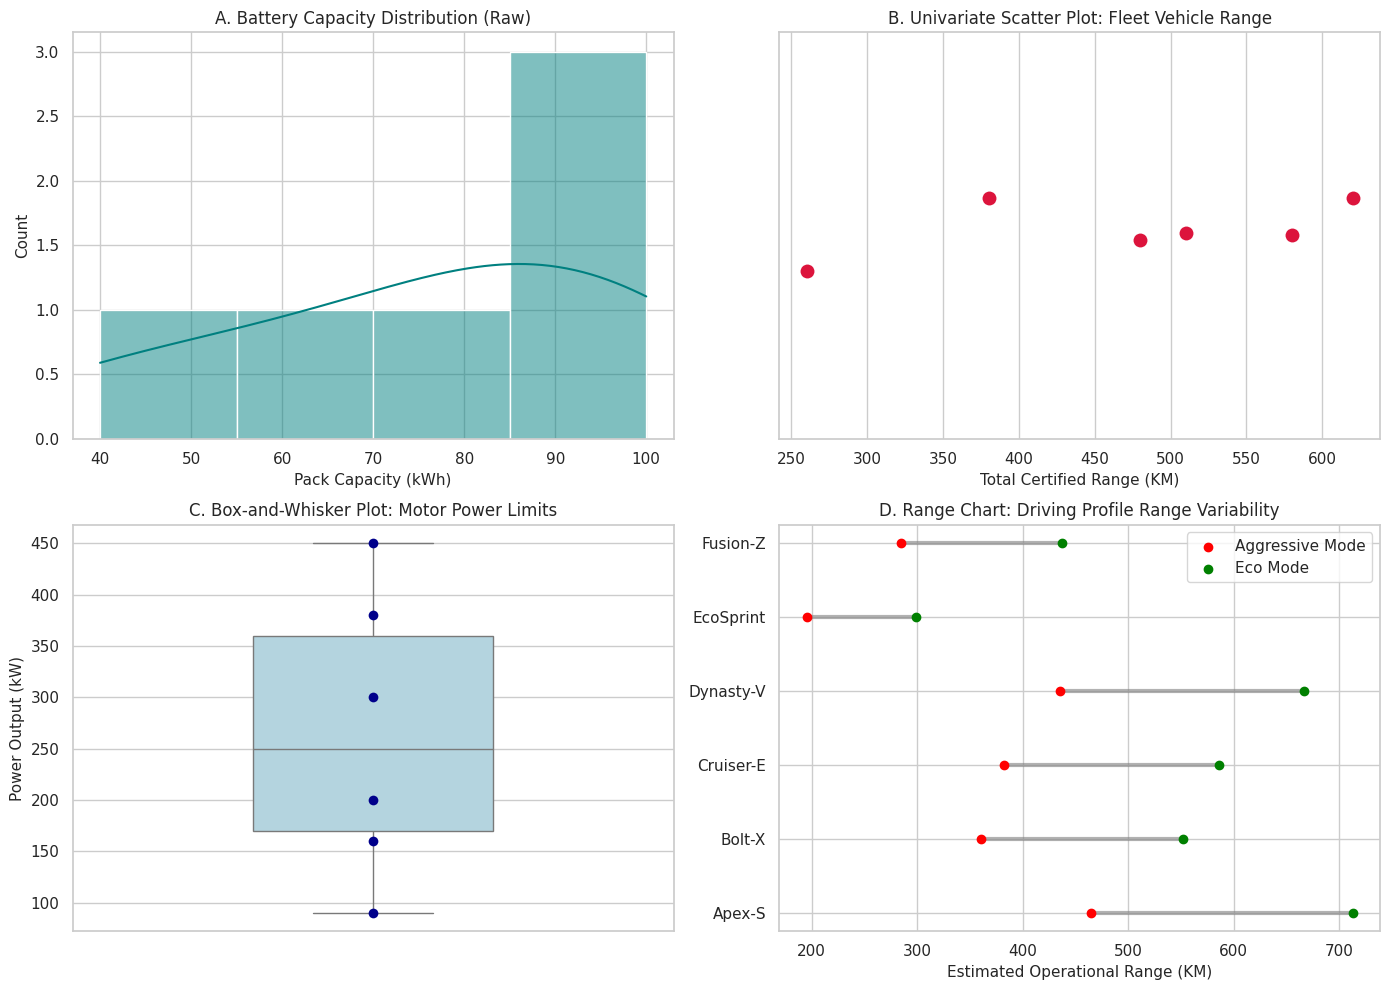

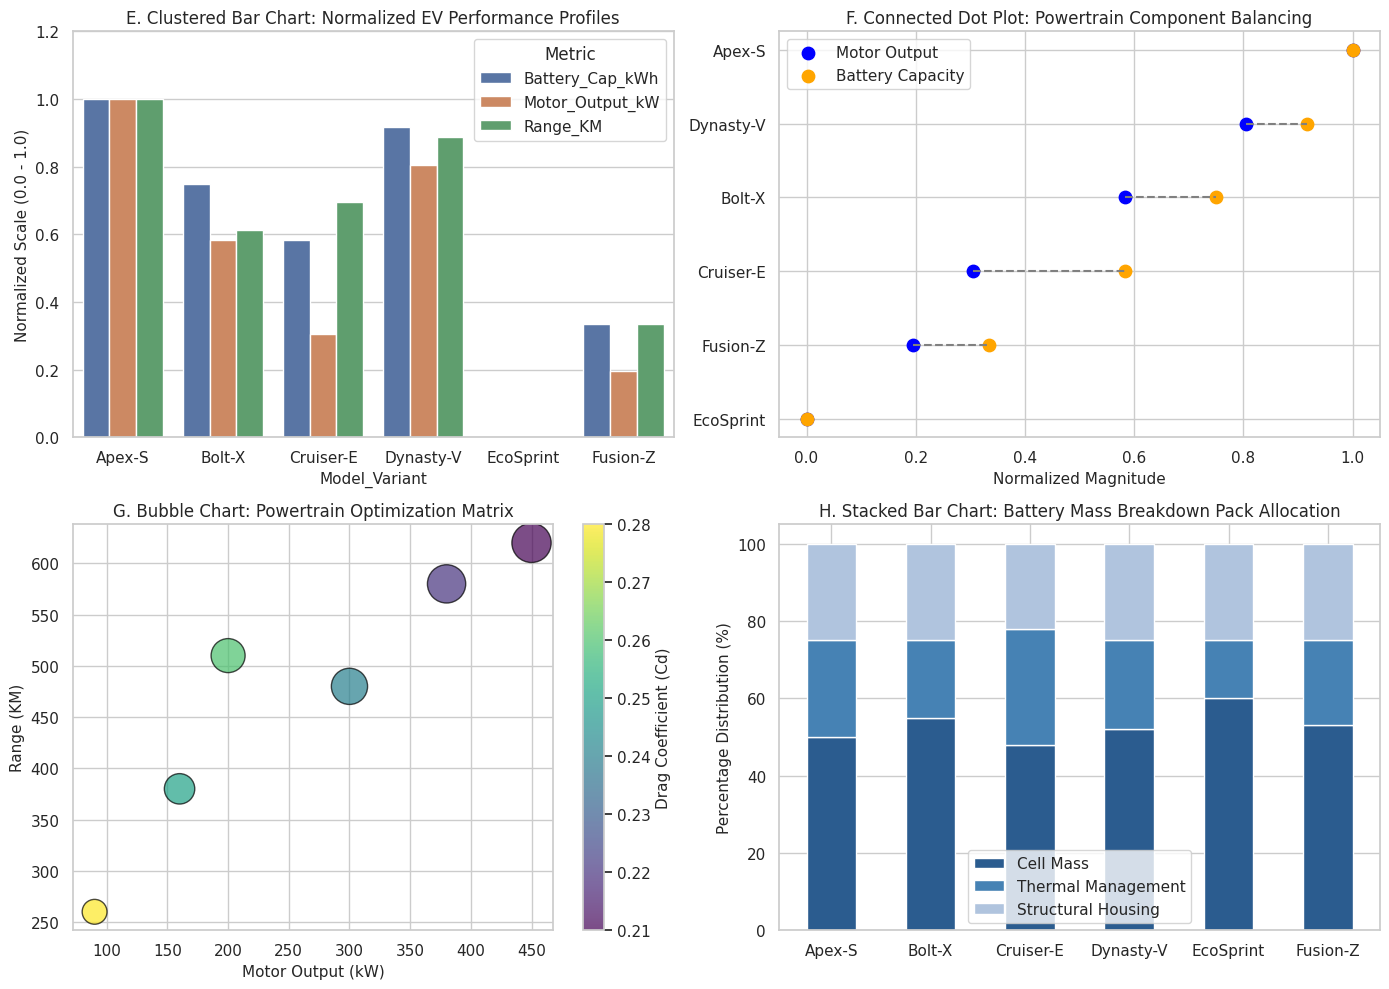

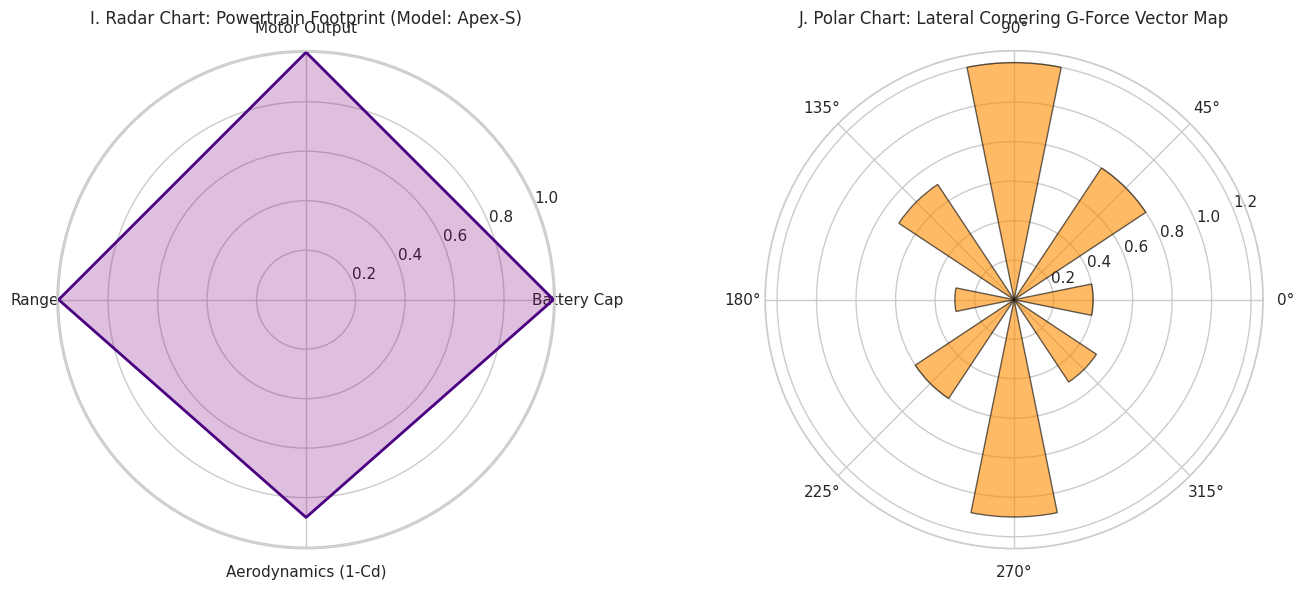

(np.float64(-0.5), np.float64(399.5), np.float64(399.5), np.float64(-0.5))

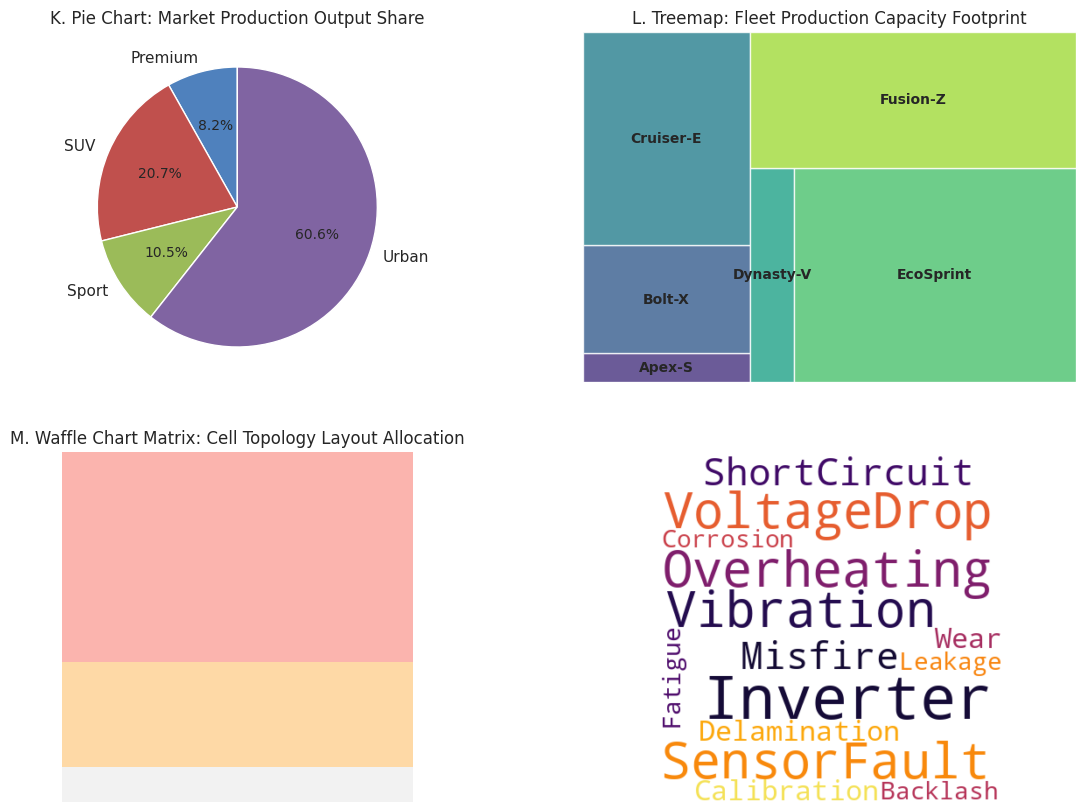

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import squarify  # For Treemap
from sklearn.preprocessing import MinMaxScaler

# Initialize the plotting style for clean engineering graphics
sns.set_theme(style="whitegrid")
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11

# =====================================================================
# 1. SETUP AUTOMOTIVE CASE STUDY DATASET & DATA NORMALIZATION
# =====================================================================
# Telemetry tracking simulated EV models on an indoor dyno test circuit
ev_data = {
    'Model_Variant': ['Apex-S', 'Bolt-X', 'Cruiser-E', 'Dynasty-V', 'EcoSprint', 'Fusion-Z'],
    'Battery_Cap_kWh': [100.0, 85.0, 75.0, 95.0, 40.0, 60.0],
    'Motor_Output_kW': [450.0, 300.0, 200.0, 380.0, 90.0, 160.0],
    'Range_KM': [620.0, 480.0, 510.0, 580.0, 260.0, 380.0],
    'Drag_Coefficient': [0.21, 0.24, 0.26, 0.22, 0.28, 0.25],
    'Market_Segment': ['Premium', 'Sport', 'SUV', 'Premium', 'Urban', 'Urban'],
    'Fleet_Production_Count': [1200, 4500, 8900, 2300, 15000, 11000]
}

df = pd.DataFrame(ev_data)

# Perform Min-Max Data Normalization on Performance Variables
norm_cols = ['Battery_Cap_kWh', 'Motor_Output_kW', 'Range_KM']
scaler = MinMaxScaler()
df_norm = df.copy()
df_norm[norm_cols] = scaler.fit_transform(df[norm_cols])

# =====================================================================
# VISUALIZATION GROUP 1: STATISTICAL DISTRIBUTIONS & UNIVARIATE ANALYSIS
# =====================================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# A. Histogram: Battery Capacity Distribution
sns.histplot(data=df, x='Battery_Cap_kWh', bins=4, kde=True, ax=axes[0, 0], color='teal')
axes[0, 0].set_title("A. Battery Capacity Distribution (Raw)")
axes[0, 0].set_xlabel("Pack Capacity (kWh)")

# B. Univariate Scatter Plot: Range Telemetry Distribution
sns.stripplot(data=df, x='Range_KM', color='crimson', size=10, jitter=0.1, ax=axes[0, 1])
axes[0, 1].set_title("B. Univariate Scatter Plot: Fleet Vehicle Range")
axes[0, 1].set_xlabel("Total Certified Range (KM)")

# C. Box-and-Whisker Plot: Motor Output Across Fleet
sns.boxplot(data=df, y='Motor_Output_kW', color='lightblue', width=0.4, ax=axes[1, 0])
sns.swarmplot(data=df, y='Motor_Output_kW', color='darkblue', size=7, ax=axes[1, 0])
axes[1, 0].set_title("C. Box-and-Whisker Plot: Motor Power Limits")
axes[1, 0].set_ylabel("Power Output (kW)")

# D. Range Chart: Maximum vs Minimum Expected Fleet Operating Windows
# Simulating variation bands under aggressive vs eco driving profiles
y_pos = np.arange(len(df['Model_Variant']))
range_min = df['Range_KM'] * 0.75
range_max = df['Range_KM'] * 1.15
axes[1, 1].hlines(y=y_pos, xmin=range_min, xmax=range_max, color='grey', alpha=0.6, linewidth=3)
axes[1, 1].scatter(range_min, y_pos, color='red', label='Aggressive Mode', zorder=3)
axes[1, 1].scatter(range_max, y_pos, color='green', label='Eco Mode', zorder=3)
axes[1, 1].set_yticks(y_pos)
axes[1, 1].set_yticklabels(df['Model_Variant'])
axes[1, 1].set_title("D. Range Chart: Driving Profile Range Variability")
axes[1, 1].set_xlabel("Estimated Operational Range (KM)")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

# =====================================================================
# VISUALIZATION GROUP 2: POWERTRAIN PERFORMANCE PROFILES (NORMALIZED)
# =====================================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# E. Clustered Bar Chart: Normalized Comparative Metric Profiles
df_melted = df_norm.melt(id_vars='Model_Variant', value_vars=norm_cols,
                         var_name='Metric', value_name='Normalized_Value')
sns.barplot(data=df_melted, x='Model_Variant', y='Normalized_Value', hue='Metric', ax=axes[0, 0])
axes[0, 0].set_title("E. Clustered Bar Chart: Normalized EV Performance Profiles")
axes[0, 0].set_ylabel("Normalized Scale (0.0 - 1.0)")
axes[0, 0].set_ylim(0, 1.2)

# F. Connected Dot Plot: Motor Output vs Battery Efficiency Match
df_sorted = df_norm.sort_values(by='Motor_Output_kW')
axes[0, 1].scatter(df_sorted['Motor_Output_kW'], df_sorted['Model_Variant'], color='blue', label='Motor Output', s=80)
axes[0, 1].scatter(df_sorted['Battery_Cap_kWh'], df_sorted['Model_Variant'], color='orange', label='Battery Capacity', s=80)
for idx, row in df_sorted.iterrows():
    axes[0, 1].plot([row['Motor_Output_kW'], row['Battery_Cap_kWh']], [row['Model_Variant'], row['Model_Variant']], color='grey', linestyle='--')
axes[0, 1].set_title("F. Connected Dot Plot: Powertrain Component Balancing")
axes[0, 1].set_xlabel("Normalized Magnitude")
axes[0, 1].legend()

# G. Bubble Chart: Power vs Range vs Aero Constraints
# Bubble size corresponds to the Battery Capacity metric
bubble_sizes = df['Battery_Cap_kWh'] * 8
scatter = axes[1, 0].scatter(df['Motor_Output_kW'], df['Range_KM'], s=bubble_sizes,
                             c=df['Drag_Coefficient'], cmap='viridis', alpha=0.7, edgecolors='black')
axes[1, 0].set_title("G. Bubble Chart: Powertrain Optimization Matrix")
axes[1, 0].set_xlabel("Motor Output (kW)")
axes[1, 0].set_ylabel("Range (KM)")
cbar = plt.colorbar(scatter, ax=axes[1, 0])
cbar.set_label("Drag Coefficient (Cd)")

# H. Stacked Bar Chart: Powertrain Mass Breakdown (Simulated Proportions)
components = ['Cell Mass', 'Thermal Management', 'Structural Housing']
chassis_data = np.array([[50, 25, 25], [55, 20, 25], [48, 30, 22], [52, 23, 25], [60, 15, 25], [53, 22, 25]])
bottom_tracker = np.zeros(6)
colors = ['#2b5c8f', '#4682b4', '#b0c4de']

for i, comp in enumerate(components):
    axes[1, 1].bar(df['Model_Variant'], chassis_data[:, i], bottom=bottom_tracker, label=comp, color=colors[i], width=0.5)
    bottom_tracker += chassis_data[:, i]
axes[1, 1].set_title("H. Stacked Bar Chart: Battery Mass Breakdown Pack Allocation")
axes[1, 1].set_ylabel("Percentage Distribution (%)")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

# =====================================================================
# VISUALIZATION GROUP 3: MACRO RADAR & POLAR KINEMATICS
# =====================================================================
# I. Radar Chart & J. Polar Chart Setup
labels = ['Battery Cap', 'Motor Output', 'Range', 'Aerodynamics (1-Cd)']
num_vars = len(labels)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1] # Close the circular loop geometry

# Map sample vehicle configuration profile metrics (Normalized)
apex_metrics = [1.0, 1.0, 1.0, 0.88] # Apex-S Maxima normalized mapping values
apex_metrics += apex_metrics[:1]

fig = plt.figure(figsize=(14, 6))

# I. Radar Chart
ax_radar = fig.add_subplot(121, polar=True)
ax_radar.plot(angles, apex_metrics, color='indigo', linewidth=2, linestyle='solid')
ax_radar.fill(angles, apex_metrics, color='purple', alpha=0.25)
ax_radar.set_thetagrids(np.degrees(angles[:-1]), labels)
ax_radar.set_title("I. Radar Chart: Powertrain Footprint (Model: Apex-S)", pad=20)

# J. Polar Chart: High-Speed Test Track Cornering Forces Vector
# Simulating multi-directional structural loading parameters
polar_angles = np.radians([0, 45, 90, 135, 180, 225, 270, 315])
lateral_g_forces = [0.4, 0.8, 1.2, 0.7, 0.3, 0.6, 1.1, 0.5]
ax_polar = fig.add_subplot(122, polar=True)
ax_polar.bar(polar_angles, lateral_g_forces, width=0.4, color='darkorange', alpha=0.6, edgecolor='black')
ax_polar.set_title("J. Polar Chart: Lateral Cornering G-Force Vector Map", pad=20)

plt.tight_layout()
plt.show()

# =====================================================================
# VISUALIZATION GROUP 4: PRODUCTION VOLUME & COMMUNICATIVE GRAPHICS
# =====================================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# K. Pie Chart: Market Segment Production Allocation Share
segment_shares = df.groupby('Market_Segment')['Fleet_Production_Count'].sum()
axes[0, 0].pie(segment_shares, labels=segment_shares.index, autopct='%1.1f%%',
               colors=['#4f81bd', '#c0504d', '#9bbb59', '#8064a2'], startangle=90,
               wedgeprops={'edgecolor': 'white', 'linewidth': 1})
axes[0, 0].set_title("K. Pie Chart: Market Production Output Share")

# L. Treemap: Production Volume Fleet Component Sizing
colors_tree = sns.color_palette("viridis", len(df))
squarify.plot(sizes=df['Fleet_Production_Count'], label=df['Model_Variant'],
               color=colors_tree, alpha=0.8, ax=axes[0, 1], text_kwargs={'fontsize':10, 'weight':'bold'})
axes[0, 1].axis('off')
axes[0, 1].set_title("L. Treemap: Fleet Production Capacity Footprint")

# M. Waffle Chart (Emulated Matrix Layout via Subplot Axes Configuration)
# Simulating modular battery cell array arrangements (10x10 pack template)
waffle_grid = np.zeros((10, 10))
waffle_grid[:6, :] = 1  # 60% Active Safe Cells
waffle_grid[6:9, :] = 2 # 30% Regenerative Reserve Cells
waffle_grid[9, :] = 3   # 10% Thermal Buffer Isolation zones
axes[1, 0].imshow(waffle_grid, cmap='Pastel1')
axes[1, 0].set_xticks(np.arange(-.5, 10, 1), minor=True)
axes[1, 0].set_yticks(np.arange(-.5, 10, 1), minor=True)
axes[1, 0].grid(which='minor', color='w', linestyle='-', linewidth=2)
axes[1, 0].axis('off')
axes[1, 0].set_title("M. Waffle Chart Matrix: Cell Topology Layout Allocation")

# N. Word Cloud: Component Failure Report Failure Mode Logs
failure_keywords = (
    "Inverter Inverter Inverter Overheating Overheating ShortCircuit "
    "Misfire Vibration Vibration Delamination Calibration Wear Corrosion "
    "VoltageDrop VoltageDrop SensorFault SensorFault Leakage Fatigue Backlash"
)
wordcloud = WordCloud(width=400, height=400, background_color='white',
                      colormap='inferno').generate(failure_keywords)
axes[1, 1].imshow(wordcloud, interpolation='bilinear')
axes[1, 1].axis('off')



**Experiment 7: Graph data visualization**

Graph Data Visualization refers specifically to Network Theory/Graph Database modeling (Nodes and Edges). It is heavily utilized for complex relational tasks such as compiling a hierarchical Bill of Materials (BOM), tracking cross-functional ECU/CAN Bus networks, and conducting Fault Tree Analysis (FTA) for vehicle diagnostic systems.
This experiment implements a Vehicle Subsystem Dependency & Fault Diagnostics Graph using Python's networkx and matplotlib libraries, mapping how a single component failure ripples through connected nodes.

* Bill of Materials (BOM) Tree Structures: Graphs map nested product sub-assemblies flawlessly. A parent node (e.g., Chassis Assembly) forks out cleanly into children nodes (Control Arms, Knuckles, Hub Assemblies), bypassing the cell-nesting limits of flat SQL data tables.
* Cascading Fault Diagnostics (Root Cause Analysis): In this experiment, the algorithm maps an isolated hardware breakdown (Alternator Failure). NetworkX traces the relational edges downstream to alert field engineers that the Battery, ECU, Fuel Pump, and ABS Module are structurally compromised by extension, illustrating why multi-system dashboards light up simultaneously during electrical faults.
* CAN Bus Topology Modeling: Nodes can mirror physical network gateways. The edge configurations track data bandwidth loads across the vehicle multiplex network topology, making high-latency nodes immediately recognizable.


In [8]:
pip install networkx

Note: you may need to restart the kernel to use updated packages.


=== AUTOMOTIVE GRAPH DIAGNOSTICS CASE STUDY ===
Primary Fault Origin Root Cause: Alternator
Downstream Dependent Components Impacted: ['ECU', 'ABS_Module', 'Battery', 'Brake_Actuator', 'Engine_Cylinder', 'Fuel_Injector', 'Fuel_Pump']



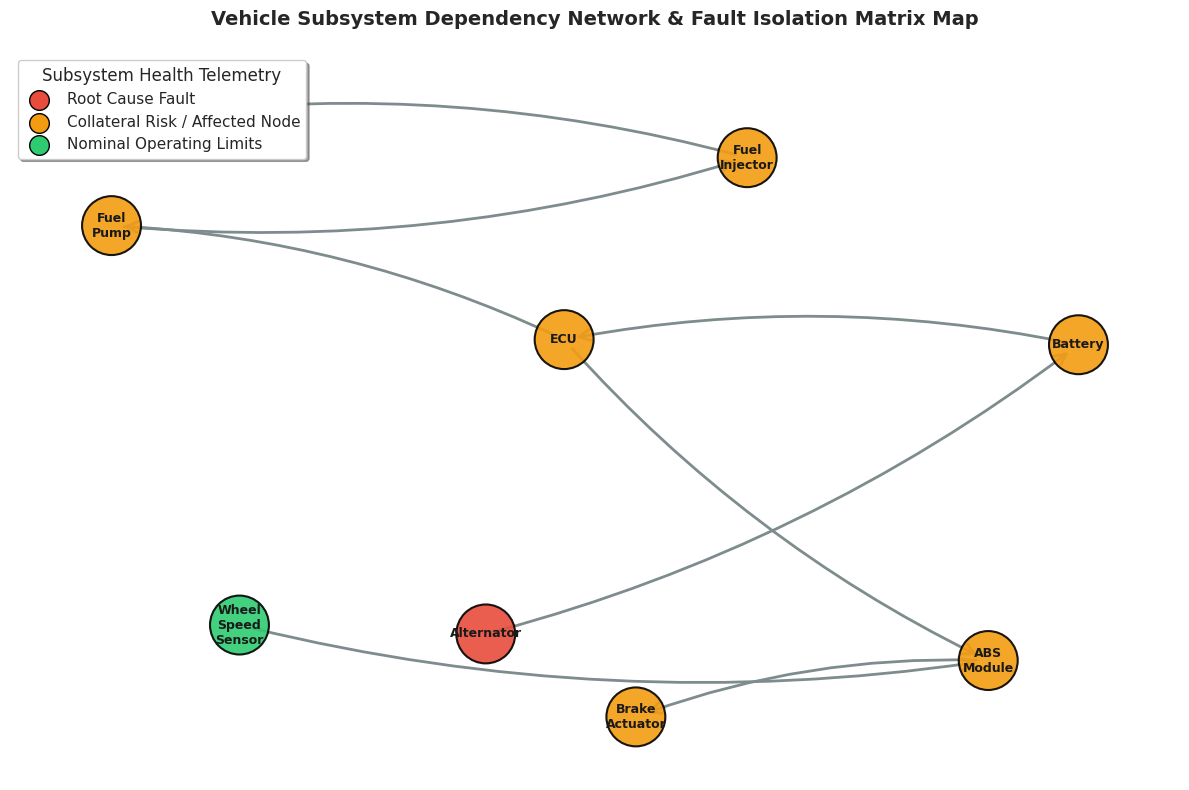

In [9]:
import networkx as nx
import matplotlib.pyplot as plt

# =====================================================================
# 1. INITIALISE GRAPH TOPOLOGY FOR VEHICLE SYSTEMS
# =====================================================================
# Creating a directional network structure mapping subsystem hierarchies
G = nx.DiGraph()

# Add Nodes representing Core Automotive Subsystems and Components
# Attributes track the structural layer and active diagnostic status
components = {
    'ECU': {'layer': 'Control', 'status': 'Normal'},
    'Battery': {'layer': 'Power', 'status': 'Normal'},
    'Alternator': {'layer': 'Power', 'status': 'Faulty'}, # Trigger node
    'Fuel_Pump': {'layer': 'Powertrain', 'status': 'Degraded'},
    'Fuel_Injector': {'layer': 'Powertrain', 'status': 'Normal'},
    'Engine_Cylinder': {'layer': 'Mechanical', 'status': 'Normal'},
    'ABS_Module': {'layer': 'Chassis', 'status': 'Normal'},
    'Brake_Actuator': {'layer': 'Mechanical', 'status': 'Normal'},
    'Wheel_Speed_Sensor': {'layer': 'Sensor', 'status': 'Normal'}
}

for node, attrs in components.items():
    G.add_node(node, layer=attrs['layer'], status=attrs['status'])

# Add Edges defining physical or electronic dependencies (Source -> Dependant)
dependencies = [
    ('Battery', 'ECU'),
    ('Alternator', 'Battery'),
    ('ECU', 'Fuel_Pump'),
    ('ECU', 'ABS_Module'),
    ('Fuel_Pump', 'Fuel_Injector'),
    ('Fuel_Injector', 'Engine_Cylinder'),
    ('ABS_Module', 'Brake_Actuator'),
    ('Wheel_Speed_Sensor', 'ABS_Module')
]

G.add_edges_from(dependencies)

# =====================================================================
# 2. RUN GRAPH DIAGNOSTIC PROPAGATION (LAB ANALYSIS)
# =====================================================================
# Programmatically identifying downstream systems affected by the 'Alternator' fault
trigger_node = 'Alternator'
affected_nodes = list(nx.descendants(G, trigger_node))

print(f"=== AUTOMOTIVE GRAPH DIAGNOSTICS CASE STUDY ===")
print(f"Primary Fault Origin Root Cause: {trigger_node}")
print(f"Downstream Dependent Components Impacted: {affected_nodes}\n")

# =====================================================================
# 3. GRAPH VISUALIZATION & GEOMETRIC LAYOUT SPECIFICATIONS
# =====================================================================
plt.figure(figsize=(12, 8))

# Map spatial layout coordinates via spring layout mechanics
pos = nx.spring_layout(G, seed=42, k=1.5)

# Establish color schema mapping for node diagnostic severity states
node_colors = []
for node in G.nodes:
    status = G.nodes[node]['status']
    if status == 'Faulty':
        node_colors.append('#e74c3c')   # Vivid Red
    elif status == 'Degraded' or node in affected_nodes:
        node_colors.append('#f39c12')   # Amber Warning
    else:
        node_colors.append('#2ecc71')   # Clean Green

# Draw Network Base Geometry Elements
nx.draw_networkx_nodes(
    G, pos,
    node_color=node_colors,
    node_size=1800,
    edgecolors='black',
    linewidths=1.5,
    alpha=0.9
)

# Render crisp multi-layer vector edge lines
nx.draw_networkx_edges(
    G, pos,
    edgelist=dependencies,
    width=2,
    edge_color='#7f8c8d',
    arrowsize=20,
    arrowstyle='->',
    connectionstyle='arc3,rad=0.1'
)

# Superimpose human-readable typography text tags
labels = {node: node.replace('_', '\n') for node in G.nodes}
nx.draw_networkx_labels(G, pos, labels=labels, font_size=9, font_weight='bold', font_family='sans-serif')

# Create a clean visual engineering legend proxy interface layout
plt.scatter([], [], c='#e74c3c', edgecolors='black', s=200, label='Root Cause Fault')
plt.scatter([], [], c='#f39c12', edgecolors='black', s=200, label='Collateral Risk / Affected Node')
plt.scatter([], [], c='#2ecc71', edgecolors='black', s=200, label='Nominal Operating Limits')
plt.legend(title="Subsystem Health Telemetry", loc="upper left", frameon=True, shadow=True, facecolor='white')

plt.title("Vehicle Subsystem Dependency Network & Fault Isolation Matrix Map", fontsize=14, weight='bold', pad=20)
plt.axis('off')
plt.tight_layout()
plt.show()
